# Práctica 1: Redes Neuronales Densas (EuroSAT)
## Aprendizaje Profundo - Grado en Inteligencia Artificial
**Universidade da Coruña (UDC)**

---

### Información del Grupo de Prácticas
* **Autores:** Xoel Sánchez Dacoba y Sebastián David Moreno Expósito
* **Código del Grupo de Prácticas:** [Ej. Grupo_XX]
* **Fecha:** Noviembre 2026
* **Dataset:** EuroSAT RGB (Sentinel-2, 10 clases de uso de suelo)

---

## Índice de Contenidos
1. **[Configuración del Entorno y Reproducibilidad](#sec1)**
2. **[Carga y Exploración del Dataset EuroSAT](#sec2)**
3. **[Preprocesado del Dataset](#sec3)**
   * Partición Train / Validation / Test
   * Normalización $[0, 1]$
   * Codificación One-Hot
   * Aplanado de Imágenes (Vector $64\times 64\times 3 = 12.288$)
4. **[Metodología Experimental y Funciones de Apoyo](#sec4)**
5. **[Modelo 1: Red Neuronal Densa Base (Vanilla MLP Baseline)](#sec5)**
6. **[Experimentación con Medidas de Regularización](#sec6)**
   * 6.1. *Modelo 2: Regularización de Pesos ($L_2$ / Weight Decay)*
   * 6.2. *Modelo 3: Regularización por Dropout*
   * 6.3. *Modelo 4: Parada Temprana (Early Stopping)*
   * 6.4. *Modelo 5: Normalización por Lotes (Batch Normalization)*
   * 6.5. *Modelo 6: Combinación Óptima de Regularizadores*
7. **[Comparación Global de Resultados y Evaluación en Test](#sec7)**
8. **[Conclusiones y Justificación Teórica](#sec8)**

<a id="sec1"></a>
## 1. Configuración del Entorno y Reproducibilidad

En esta sección importamos las librerías necesarias para el desarrollo del proyecto (tensorflow, keras, tensorflow_datasets, numpy, matplotlib, pandas, sklearn) y establecemos una semilla aleatoria global fija (SEED = 255256).

> La fijación de la semilla en `PYTHONHASHSEED`, `random`, `numpy` y `tensorflow` garantiza que las particiones de datos, las inicializaciones de pesos y el entrenamiento sean completamente reproducibles.

In [2]:
import os
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
import tensorflow_datasets as tfds
from sklearn.metrics import classification_report, confusion_matrix

SEED = 255256#Fijo como constante para reproducibilidad
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow v: {tf.__version__}")
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print(f"GPU detectada: {gpus}")
else:
    print("No se detectó GPU")

I0000 00:00:1793728027.766774    1120 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow v: 2.21.0
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


<a id='sec2'></a>
## 2. Carga y Exploración del Dataset EuroSAT

EuroSAT es un conjunto de datos basado en imágenes ópticas multiespectrales del satélite **Sentinel-2** de la Agencia Espacial Europea (ESA), ampliamente utilizado para la clasificación de usos del suelo y coberturas de terreno (*Land Use and Land Cover - LULC*).

Características principales del dataset:
* **Número total de imágenes:** 27.000 imágenes RGB.
* **Resolución:** $64 \times 64$ píxeles por imagen, con 3 canales de color (Rojo, Verde, Azul).
* **Número de clases:** 10 clases temáticas (Bosques, Ríos, Carreteras, Zonas Residenciales, Industriales, Cultivos, etc.).
* **Distribución:** Entre 2.000 y 3.000 imágenes por clase (distribución ligeramente no uniforme).

Cargamos el dataset a través de tensorflow_datasets (eurosat/rgb).

In [3]:
dataset_name = "eurosat/rgb"
raw_ds, ds_info = tfds.load(dataset_name, with_info=True, as_supervised=True)

class_names = ds_info.features["label"].names
num_classes = ds_info.features["label"].num_classes
tot_examples = ds_info.splits["train"].num_examples

print(f"Total de ejemplos: {tot_examples}")
print(f"Número de clases: {num_classes}")
print("Nombres de clases:")
for idx, name in enumerate(class_names):
    print(f"  [{idx}] {name}")

Total de ejemplos: 27000
Número de clases: 10
Nombres de clases:
  [0] AnnualCrop
  [1] Forest
  [2] HerbaceousVegetation
  [3] Highway
  [4] Industrial
  [5] Pasture
  [6] PermanentCrop
  [7] Residential
  [8] River
  [9] SeaLake


I0000 00:00:1793728035.742001    1120 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4045 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:08:00.0, compute capability: 7.5


### Visualización de Muestras del Dataset

Inspeccionamos visualmente una imagen representativa de cada una de las 10 categorías de terreno para comprender la naturaleza visual y la complejidad del problema.

I0000 00:00:1793728038.171398    2377 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608
W0000 00:00:1793728038.191671    1120 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


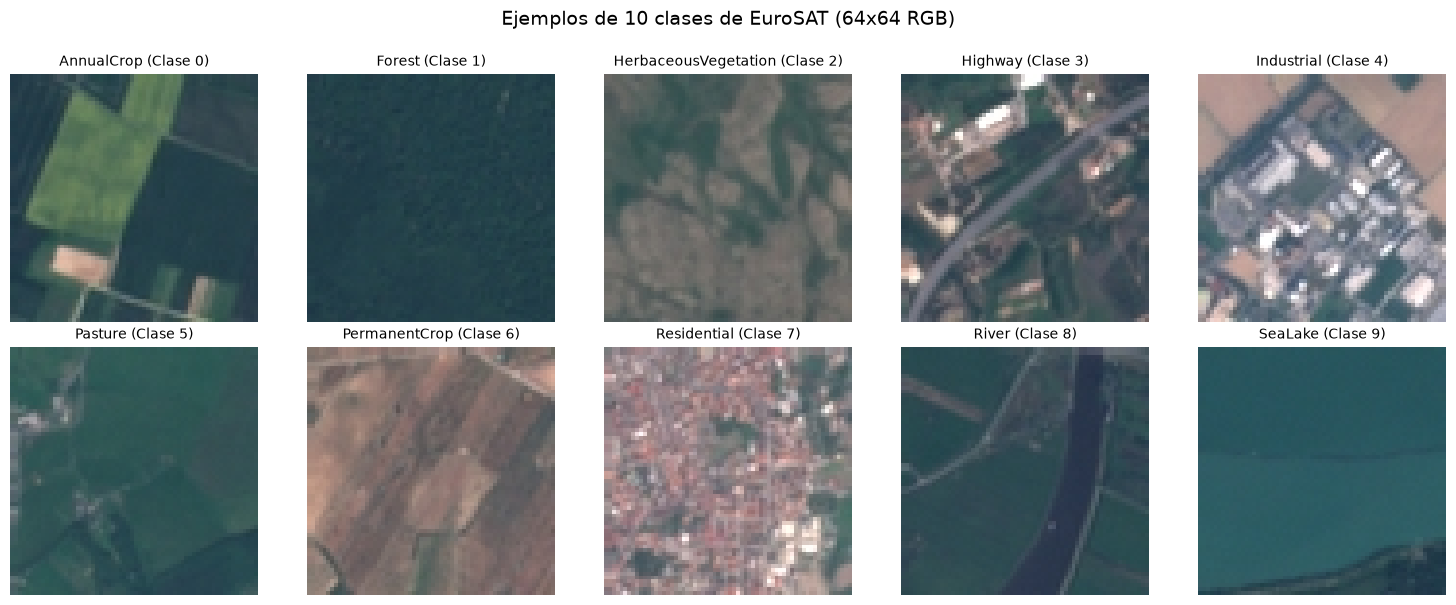

In [4]:
samples_per_class = {}#No es lo más eficiente, pero solo es para visualizar
for img, label in raw_ds["train"]:
    lbl = int(label.numpy())
    if lbl not in samples_per_class:
        samples_per_class[lbl] = img.numpy()
    if len(samples_per_class) == num_classes:
        break

plt.figure(figsize=(15, 6))
for i in range(num_classes):
    plt.subplot(2, 5, i + 1)
    plt.imshow(samples_per_class[i])
    plt.title(f"{class_names[i]} (Clase {i})", fontsize=10)
    plt.axis("off")
plt.suptitle("Ejemplos de 10 clases de EuroSAT (64x64 RGB)", fontsize=14, y=1)
plt.tight_layout()
plt.show()

#### Análisis
> Las imágenes no son especialmente nítidas debido a que se trata de parches satelitales de baja resolución espacial, por lo que a esta escala no se aprecian detalles finos ni contornos definidos. Existe un solapamiento visual muy marcado entre AnnualCrop (cultivos anuales), PermanentCrop (cultivos permanentes), Pasture (pastizales) y HerbaceousVegetation (vegetación herbácea) al estar todas ellas dominadas por tonalidades verdes lo que seguramente se traduzca en confusión inter-clase. También es probable que de problemas la ambigüedad de forma entre rios y autopistas y las texturas de los materiales en las clases de zonas urbanas e industriales.

<a id="sec3"></a>
## 3. Preprocesado del Dataset

De acuerdo con los requisitos especificados en el enunciado de la practica, aplicamos las siguientes transformaciones al dataset:

1. **Partición en Entrenamiento, Validación y Test:**
   EuroSAT viene como un bloque único de 27.000 imágenes. Realizamos una partición en proporción 70% Entrenamiento (18.900 imgs), 15% Validación (4.050 imgs) y 15% Test (4.050 imgs).
2. **Normalización de píxeles al rango [0, 1]:**
    Convertimos los valores de los píxeles de enteros [0, 255] a punto flotante float32 dividiendo entre 255.0. Esto estabiliza el descenso por gradiente y acelera la convergencia.
3. **Codificación One-Hot de las Etiquetas:**
    Transformamos cada etiqueta entera (en el dataset del 0 al 9)en un vector disperso de dimensión 10 con un 1 en la posición de la clase correspondiente, adecuado para la pérdida categorical_crossentropy.
4. **Aplanado de la Imagen:**
   Dado que la práctica exige el uso de redes neuronales densas (Vanilla NNs) y no convolucionales, cada imagen de dimensiones $64 \times 64 \times 3$ se aplana a un vector unidimensional de $64 \cdot 64 \cdot 3 = 12.288$ características de entrada.

In [5]:
(raw_train, raw_val, raw_test) = tfds.load(# Partimos el dataset en 70% Train, 15% Validation y 15% Test
    "eurosat/rgb",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    shuffle_files=True
)

INPUT_SHAPE = 64 * 64 * 3  # 12288 entradas, ya que cada imagen es de 64x64 píxeles y tiene 3 canales (RGB)

def preprocess_sample(image, label):
    """
    Preprocesado de cada muestra de EuroSAT:
    - Normalización a [0.0, 1.0]
    - Aplanado de matriz 64x64x3 al vector 12288
    - Codificación One-Hot de la etiqueta (10 clases)
    """
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.reshape(image, [INPUT_SHAPE])
    label = tf.one_hot(label, depth=num_classes)
    return image, label

BATCH_SIZE = 64# Tamaño del lote, 64 para mi 2060 RTX es un buen compromiso entre velocidad y memoria

train_ds = (raw_train #Prefetching y paralelización de pipelines
            .map(preprocess_sample, num_parallel_calls=tf.data.AUTOTUNE)#Autotune permite crear un pool de hilos para aprovechar los nucleos de la CPU
            .cache()#Almacenamos en memoria rápida la partición de para acelerar el entrenamiento, ya que el dataset es pequeño y cabe en memoria
            .shuffle(buffer_size=10000, seed=SEED)#Aqui entra en juego la aleatorización, barajando los datos en cada época 
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

val_ds = (raw_val
          .map(preprocess_sample, num_parallel_calls=tf.data.AUTOTUNE)
          .cache()
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

test_ds = (raw_test
           .map(preprocess_sample, num_parallel_calls=tf.data.AUTOTUNE)
           .cache()
           .batch(BATCH_SIZE)
           .prefetch(tf.data.AUTOTUNE))

print("pipelines de tf.data configurados")

pipelines de tf.data configurados


### Verificación de Formas y Rangos de Datos

Comprobamos las dimensiones de los tensores generados por el pipeline para asegurar que cumplen con el contrato esperado antes del modelado.

In [6]:
for sample_x, sample_y in train_ds.take(1):#Donde sample_x es un lote de imágenes y sample_y es un lote de etiquetas
    print(f"Forma del lote de entrada (X): {sample_x.shape} (Batch de 12288 características)")
    print(f"Forma del lote de etiquetas (y): {sample_y.shape} (Batch, 10 clases one-hot)")
    print(f"Rango de valores de entrada: [{sample_x.numpy().min()}, {sample_x.numpy().max()}]")
    print(f"Ejemplo de etiqueta codificada en One-Hot:\n{sample_y.numpy()[0]}")
    assert sample_x.shape[1] == 12288, "Error: La dimensión de entrada aplanada debe ser 12288."#Hacemos assert para verificar dimensiones
    assert sample_y.shape[1] == 10, "Error: La dimensión de salida debe ser 10."

Forma del lote de entrada (X): (64, 12288) (Batch de 12288 características)
Forma del lote de etiquetas (y): (64, 10) (Batch, 10 clases one-hot)
Rango de valores de entrada: [0.05882352963089943, 1.0]
Ejemplo de etiqueta codificada en One-Hot:
[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


W0000 00:00:1793728045.328661    2523 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
W0000 00:00:1793728045.332804    2523 cache_dataset_ops.cc:912] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


<a id="sec4"></a>
## 4. Metodología Experimental y Funciones de Apoyo

Para garantizar un análisis riguroso y sistemático de cada modelo, definimos:
1. **plot_training_history(history, model_title):** Visualiza las curvas de entrenamiento y validación de la función de pérdida (*Loss*) y la exactitud (*Accuracy*).
2. **evaluate_and_log(model_name, model, history, training_time):** Evalúa el modelo en el conjunto de **Test** independiente y registra sus métricas en un diccionario común para la tabla comparativa final.
3. **Hiperparámetros comunes de referencia:**
   * Optimizador:Adam con tasa de aprendizaje inicial $\eta$ = 10^(-3).
   * Función de pérdida: categorical_crossentropy
   * Métrica de monitorización: accuracy
   * Épocas(epochs) máximas: 25 a 35

In [ ]:
results_registry = {}# Diccionario a modo de registro global donde almacenaremos las métricas de todos los modelos

def plot_training_history(history, model_name="Modelo"):
    """Genera gráficos lado a lado de la evolución de Loss y Accuracy."""
    epochs = range(1, len(history.history["loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    
    # Loss
    ax1.plot(epochs, history.history["loss"], label="Train Loss", color="#1c6ca5", lw=2)#Desde cuando en plt color tiene un selector de display de color?
    ax1.plot(epochs, history.history["val_loss"], label="Val Loss", color="#ff7f0e", lw=2, linestyle="--")
    ax1.set_title(f"{model_name} - Función de Loss", fontsize=12)
    ax1.set_xlabel("Época")
    ax1.set_ylabel("Categorical Crossentropy")
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ###
    # Accuracy
    ax2.plot(epochs, history.history["accuracy"], label="Train Accuracy", color="#1c6ca5", lw=2)
    ax2.plot(epochs, history.history["val_accuracy"], label="Val_Accuracy", color="#ff7f0e", lw=2, linestyle="--")
    ax2.set_title(f"{model_name} - Accuracy", fontsize=12)
    ax2.set_xlabel("Época")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ###
    plt.tight_layout()
    plt.show()

def evaluate_and_log(model_name, model, history, train_time):
    """Evalúa en Test y registra las métricas consolidadas en el registro global."""
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    final_train_loss = history.history["loss"][-1]#Cogemos último valor(el primero empezando desde atrás(-1)) de loss y accuracy de entrenamiento y validación
    final_val_loss = history.history["val_loss"][-1]
    final_train_acc = history.history["accuracy"][-1]
    final_val_acc = history.history["val_accuracy"][-1]
    epochs_trained = len(history.history["loss"])
    
    results_registry[model_name] = {
        "Épocas": epochs_trained,
        "Train Loss": round(final_train_loss, 4),
        "Val Loss": round(final_val_loss, 4),
        "Test Loss": round(test_loss, 4),
        "Train Acc (%)": round(final_train_acc * 100, 2),
        "Val Acc (%)": round(final_val_acc * 100, 2),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Tiempo (s)": round(train_time, 1)
    }
    print(f"\n✓ [{model_name}] Registrado: Test Acc = {test_acc*100}% | Test Loss = {test_loss} | Tiempo = {train_time}s")

<a id="sec5"></a>
## 5. Modelo 1: Red Neuronal Densa Base (Vanilla MLP Baseline)

Construimos una arquitectura densa (*Multi-Layer Perceptron*) sencilla, sin ninguna técnica de regularización:
* **Capa de entrada:** 12.288 neuronas (píxeles aplanados).
* **Capas ocultas:**
  * Capa Oculta 1: 512 neuronas con activación ReLU.
  * Capa Oculta 2: 256 neuronas con activación ReLU.
  * Capa Oculta 3: 128 neuronas con activación ReLU.
* **Capa de salida:** 10 neuronas con activación Softmax (distribución sobre las 10 clases).

> **Hipótesis teórica:** Dada la alta dimensionalidad de entrada (12.288) y la gran cantidad de parámetros entrenables (más de 6 millones), el modelo base memorizará con facilidad las muestras de entrenamiento, mostrando un **sobreajuste (overfitting) temprano y severo**(muy probablemente), caracterizado por una brecha creciente entre la pérdida de entrenamiento y la de validación.

Model: "Modelo_1_Vanilla_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,457,482 (24.63 MB)

 Trainable params: 6,457,482 (24.63 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


... (2 outputs left out)

I0000 00:00:1793728055.639698    2353 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


284/296 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2952 - loss: 2.0163

I0000 00:00:1793728057.399122    2355 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2070__.18


296/296 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.2986 - loss: 2.0029 - val_accuracy: 0.3481 - val_loss: 1.7652
Epoch 2/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.3914 - loss: 1.6215 - val_accuracy: 0.3970 - val_loss: 1.5629
Epoch 3/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4177 - loss: 1.5546 - val_accuracy: 0.4358 - val_loss: 1.4759
Epoch 4/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4356 - loss: 1.5035 - val_accuracy: 0.4158 - val_loss: 1.5640
Epoch 5/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4771 - loss: 1.4213 - val_accuracy: 0.4901 - val_loss: 1.4246
Epoch 6/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4934 - loss: 1.3813 - val_accuracy: 0.4921 - val_loss: 1.3811
Epoch 7/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5074 - loss: 1.3541 - val_accuracy: 0.4523 - val_loss: 1.4698
Epoch 8/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5235 - loss: 1.3162 - val_accuracy: 0.5052 - val

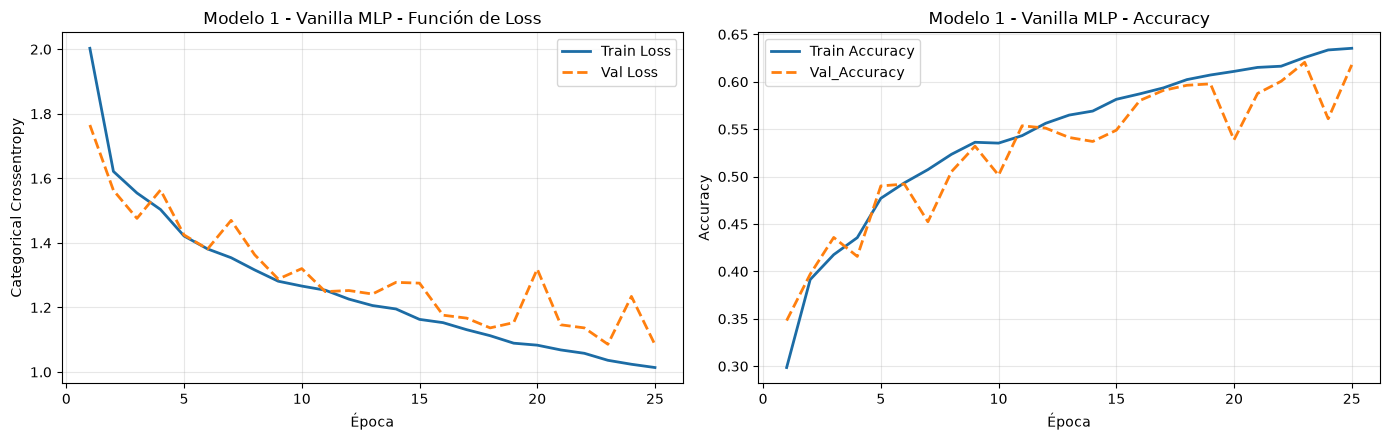


✓ [Modelo 1 (Vanilla Baseline)] Registrado: Test Acc = 62.09876537322998% | Test Loss = 1.0696303844451904 | Tiempo = 46.82476353645325s


In [8]:
def build_baseline_model()->keras.Sequential:
    """Construye un modelo MLP simple (baseline) para EuroSAT con las características explicadas anteriormente"""
    model = keras.Sequential([
        layers.Input(shape=(INPUT_SHAPE,)),
        layers.Dense(512, activation="relu", name="dense_1"),
        layers.Dense(256, activation="relu", name="dense_2"),
        layers.Dense(128, activation="relu", name="dense_3"),
        layers.Dense(num_classes, activation="softmax", name="output")
    ], name="Modelo_1_Vanilla_Baseline")
    return model

model_1 = build_baseline_model()
model_1.summary()

model_1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()
history_1 = model_1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    verbose=1
)
time_1 = time.time() - start_time

plot_training_history(history_1, "Modelo 1 - Vanilla MLP")#Usamos nuestra función para graficar la evolución de Loss y Accuracy durante el entrenamiento
evaluate_and_log("Modelo 1 (Vanilla Baseline)", model_1, history_1, time_1)#Y recurrimos a nuestra función para evaluar en Test y registrar las métricas en el registro global

### Comentarios y Diagnóstico del Modelo 1 (Baseline)

* **Diagnóstico de sobreajuste (*Overfitting* incipiente):**  
  Durante las primeras 15-17 épocas, el modelo aprende de forma efectiva: tanto train_loss como val_loss descienden notablemente y la exactitud alcanza el ~60% en ambos conjuntos. Sin embargo, a partir de la época 18 se observa el inicio claro del sobreajuste:
  - Mientras train_loss continúa descendiendo de manera monótona hasta ~1.01, val_loss se estanca en el rango [1.08, 1.15] y comienza a exhibir picos de inestabilidad notables (rebotes en épocas 20 y 24).
  - Se abre una brecha de generalización (*generalization gap*): la exactitud de entrenamiento alcanza el 63.5% mientras que la de validación se desestabiliza oscilando entre el 56% y el 61.5%.
* **Inestabilidad del Baseline:** La trayectoria de validación muestra un patrón irregular en "dientes de sierra", lo que denota una alta sensibilidad y varianza en las actualizaciones de pesos al no contar con técnicas que suavicen la optimización.
* **Causa teórica:** Con más de 6.4 millones de parámetros (la gran mayoría concentrados en la proyección 12.288 -> 512), la red memoriza correlaciones espurias de los píxeles aplanados a partir de la época 18, justificando la necesidad de aplicar regularización (Early Stopping para frenar en torno a la época 18, L2 o Dropout para controlar los pesos y Batch Normalization para estabilizar las oscilaciones).

>Se realizaron múltiples ejecuciones independientes del Baseline, observándose una alta reproducibilidad en la dinámica: en todas ellas la red agota su capacidad de generalización en torno a la época 18-20 (estancando la pérdida de validación en ~1.10 y la exactitud en ~62%), mientras que el conjunto de entrenamiento continúa sobreajustándose. Asimismo, se repite de forma sistemática la alta volatilidad en validación, justificando la necesidad de aplicar regularización y normalización.

<a id='sec6'></a>
## 6. Experimentación con Medidas de Regularización

A continuación, introducimos de forma metodica las principales técnicas de regularización para evaluar su impacto individual y combinado sobre el control del sobreaprendizaje.

---
### 6.1. Modelo 2: Regularización de Pesos ($L_2$ / Weight Decay)

La regularización $L_2$ añade un término de penalización a la función de pérdida proporcional a la suma de los cuadrados de los pesos:
$$\mathcal{L}_{\text{reg}} = \mathcal{L}_{0} + \lambda \sum_j w_j^2$$

ESto desincentiva que la red dependa en exceso de unas pocas neuronas con pesos muy grandes, favoreciendo pesos pequeños y distribuidos de manera más homogénea (curvas de decision más suaves). Aplicamos $\lambda $= 10^(-4) en cada capa densa.

Epoch 1/25


I0000 00:00:1793728160.532745    2354 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_40970__.22


287/296 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2940 - loss: 2.1037

I0000 00:00:1793728163.375184    2354 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_40970__.22


296/296 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.2956 - loss: 2.0959 - val_accuracy: 0.3588 - val_loss: 1.7866
Epoch 2/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.3939 - loss: 1.6913 - val_accuracy: 0.4094 - val_loss: 1.6352
Epoch 3/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4221 - loss: 1.6031 - val_accuracy: 0.4153 - val_loss: 1.6010
Epoch 4/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4379 - loss: 1.5487 - val_accuracy: 0.4390 - val_loss: 1.5740
Epoch 5/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4583 - loss: 1.5120 - val_accuracy: 0.4800 - val_loss: 1.4694
Epoch 6/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4737 - loss: 1.4629 - val_accuracy: 0.4627 - val_loss: 1.4819
Epoch 7/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4854 - loss: 1.4321 - val_accuracy: 0.5027 - val_loss: 1.3971
Epoch 8/25
296/296 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4970 - loss: 1.4201 - val_accuracy: 0.4336 - val

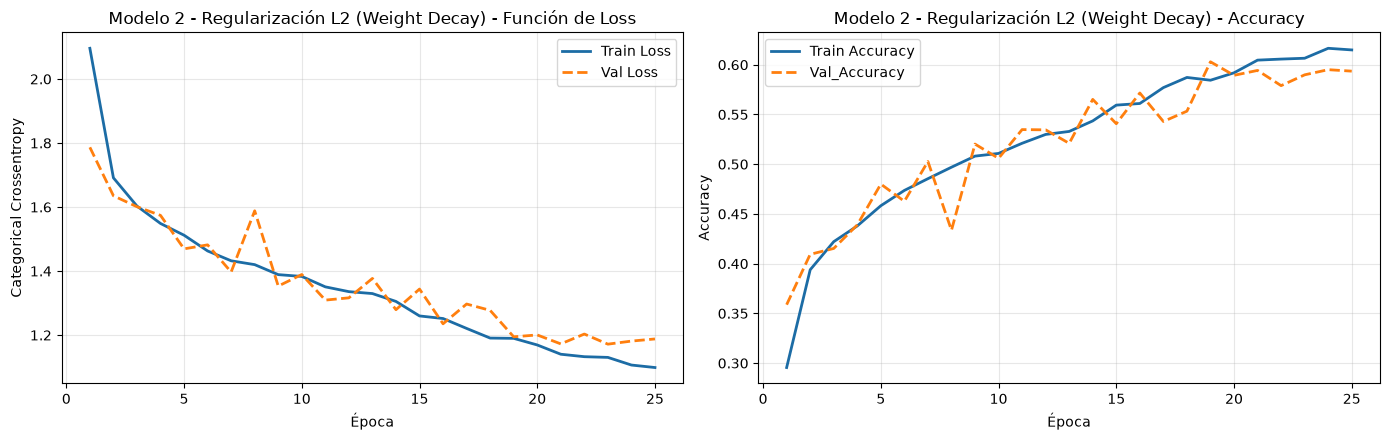


✓ [Modelo 2 (Regularización L2)] Registrado: Test Acc = 59.481483697891235% | Test Loss = 1.1732949018478394 | Tiempo = 49.10036301612854s


In [9]:
l2_factor = 1e-4#El factor de L2 aplicado como explicamos. Con esto buscamos penalizar los pesos grandes, aunque puede que lo aumentemos si vemos que sigue sobreajustando mucho 

model_2 = keras.Sequential([#Modelo 2: MLP con regularización L2 (Weight Decay)
    layers.Input(shape=(INPUT_SHAPE,)),
    layers.Dense(512, activation="relu", kernel_regularizer=regularizers.l2(l2_factor), name="dense_1_l2"),
    layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(l2_factor), name="dense_2_l2"),
    layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(l2_factor), name="dense_3_l2"),
    layers.Dense(num_classes, activation="softmax", name="output")
], name="Modelo_2_L2_Regularization")

model_2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()
history_2 = model_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    verbose=1
)
time_2 = time.time() - start_time

plot_training_history(history_2, "Modelo 2 - Regularización L2 (Weight Decay)")
evaluate_and_log("Modelo 2 (Regularización L2)", model_2, history_2, time_2)

### Comentarios del Modelo 2 ($L_2$)
* **Efecto observado:** La penalización $L_2$ modera el crecimiento descontrolado de la pérdida en validación, reduciendo la distancia entre entrenamiento y validación respecto al modelo baseline. Los pesos se mantienen acotados, evitando sobre-reacciones a detalles locales de los píxeles, aunque se sigue observando el fenomeno de picos serrados este se ha mitigado bastante.

---
### 6.2. Modelo 3: Regularización por Dropout

**Dropout** desactiva aleatoriamente una fracción p de las neuronas en cada paso de entrenamiento. Esto evita la co-adaptación de neuronas (que unas dependan críticamente de la activación de otras) y actúa como un promedio implícito de un conjunto masivo de subredes neuronales (*ensemble*).

Añadimos capas de Dropout con tasa p = 0.3 tras cada una de las capas ocultas.

Epoch 1/25


I0000 00:00:1793728219.447053    2355 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_79986__.21
I0000 00:00:1793728222.637304    2352 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_79986__.21


296/296 - 7s - 22ms/step - accuracy: 0.1766 - loss: 2.1821 - val_accuracy: 0.2499 - val_loss: 1.8975
Epoch 2/25
296/296 - 2s - 6ms/step - accuracy: 0.2240 - loss: 1.9494 - val_accuracy: 0.2901 - val_loss: 1.8157
Epoch 3/25
296/296 - 2s - 5ms/step - accuracy: 0.2500 - loss: 1.9095 - val_accuracy: 0.3398 - val_loss: 1.7814
Epoch 4/25
296/296 - 2s - 5ms/step - accuracy: 0.2616 - loss: 1.8851 - val_accuracy: 0.2948 - val_loss: 1.7580
Epoch 5/25
296/296 - 2s - 5ms/step - accuracy: 0.2705 - loss: 1.8790 - val_accuracy: 0.3405 - val_loss: 1.7047
Epoch 6/25
296/296 - 2s - 5ms/step - accuracy: 0.2767 - loss: 1.8585 - val_accuracy: 0.3336 - val_loss: 1.7079
Epoch 7/25
296/296 - 2s - 5ms/step - accuracy: 0.2762 - loss: 1.8497 - val_accuracy: 0.3296 - val_loss: 1.7751
Epoch 8/25
296/296 - 2s - 6ms/step - accuracy: 0.2799 - loss: 1.8448 - val_accuracy: 0.3128 - val_loss: 1.7568
Epoch 9/25
296/296 - 2s - 5ms/step - accuracy: 0.2849 - loss: 1.8275 - val_accuracy: 0.3217 - val_loss: 1.7145
Epoch 10/25

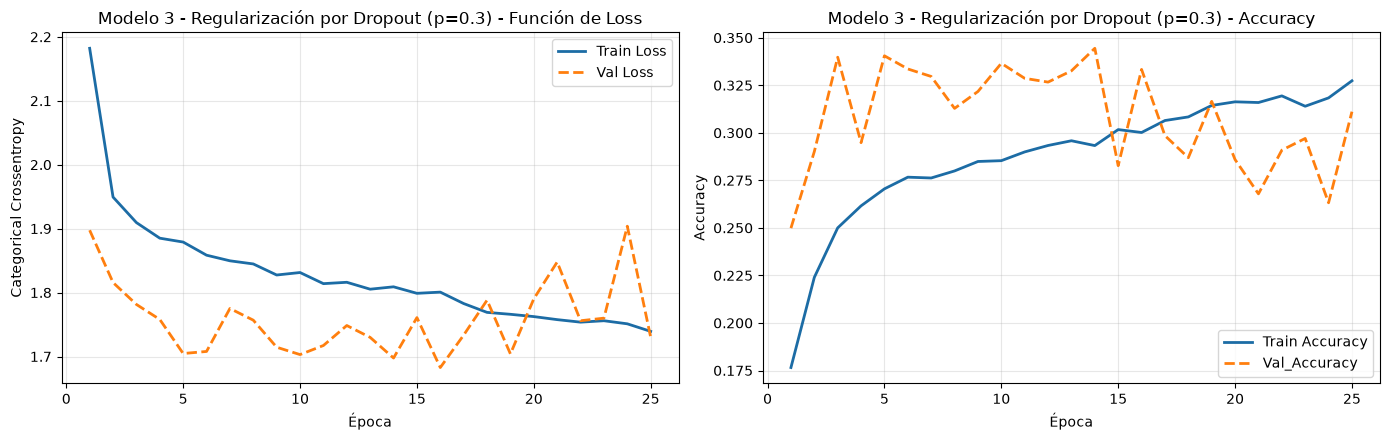


✓ [Modelo 3 (Dropout p=0.3)] Registrado: Test Acc = 31.4567893743515% | Test Loss = 1.7330131530761719 | Tiempo = 46.0836181640625s


In [10]:
dropout_rate = 0.3

model_3 = keras.Sequential([# Modelo 3: MLP con regularización por Dropout
    layers.Input(shape=(INPUT_SHAPE,)),
    layers.Dense(512, activation="relu", name="dense_1"),
    layers.Dropout(dropout_rate, name="dropout_1"),
    layers.Dense(256, activation="relu", name="dense_2"),
    layers.Dropout(dropout_rate, name="dropout_2"),
    layers.Dense(128, activation="relu", name="dense_3"),
    layers.Dropout(dropout_rate, name="dropout_3"),
    layers.Dense(num_classes, activation="softmax", name="output")
], name="Modelo_3_Dropout")

model_3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()
history_3 = model_3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    verbose=2#Pongo verbose 2 porque la barra de progreso bloatea y parpadea mucho en el notebook
)
time_3 = time.time() - start_time

plot_training_history(history_3, "Modelo 3 - Regularización por Dropout (p=0.3)")
evaluate_and_log("Modelo 3 (Dropout p=0.3)", model_3, history_3, time_3)

### Comentarios del Modelo 3 (Dropout)
* **Efecto observado (Infrajuste por exceso de regularización):**  
  - La introducción de Dropout (p=0.3) en todas las capas ocultas ralentiza drásticamente la velocidad de convergencia, limitando el accuracy final a un modesto ~38-40% en 25 épocas (frente al ~63% del Baseline y L2).
  - Se observa un fenómeno característico de Dropout: las métricas de validación son sistemáticamente mejores que las de entrenamiento (val_loss < train_loss y val_acc > train_acc). Esto se debe a que durante el entrenamiento la red opera bajo una fuerte penalización estocástica (30% de neuronas desactivadas), mientras que en validación la arquitectura completa colabora al 100%.
  - Conclusión crítica: Un valor de p=0.3 en todas las capas densas resulta excesivamente restrictivo para un horizonte de solo 25 épocas, provocando infrajuste (underfitting). Para la arquitectura final (Modelo 6) será preferible reducir la tasa de dropout (ej. p=0.15 - 0.20) o combinarlo con Batch Normalization
  

---
### 6.3. Modelo 4: Parada Temprana (Early Stopping)

**Early Stopping** monitoriza el rendimiento sobre el conjunto de validación (val_loss) y detiene automáticamente el entrenamiento cuando la métrica deja de mejorar durante un número determinado de épocas consecutivas (patience = 6).

Además, mediante restore_best_weights=True, aseguramos que los pesos finales del modelo correspondan al punto de mínima pérdida de validación y no al de la última época.

Epoch 1/35


I0000 00:00:1793728380.085918    2350 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_118714__.18
I0000 00:00:1793728382.032076    2350 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_118714__.18


296/296 - 4s - 15ms/step - accuracy: 0.2970 - loss: 1.9773 - val_accuracy: 0.3872 - val_loss: 1.6682
Epoch 2/35
296/296 - 2s - 6ms/step - accuracy: 0.3899 - loss: 1.6288 - val_accuracy: 0.3993 - val_loss: 1.5928
Epoch 3/35
296/296 - 2s - 5ms/step - accuracy: 0.4283 - loss: 1.5319 - val_accuracy: 0.4459 - val_loss: 1.4920
Epoch 4/35
296/296 - 2s - 5ms/step - accuracy: 0.4583 - loss: 1.4666 - val_accuracy: 0.4420 - val_loss: 1.5027
Epoch 5/35
296/296 - 2s - 5ms/step - accuracy: 0.4789 - loss: 1.4187 - val_accuracy: 0.4286 - val_loss: 1.5121
Epoch 6/35
296/296 - 2s - 5ms/step - accuracy: 0.4882 - loss: 1.3841 - val_accuracy: 0.4988 - val_loss: 1.3701
Epoch 7/35
296/296 - 2s - 6ms/step - accuracy: 0.5064 - loss: 1.3481 - val_accuracy: 0.5077 - val_loss: 1.3403
Epoch 8/35
296/296 - 2s - 6ms/step - accuracy: 0.5235 - loss: 1.3097 - val_accuracy: 0.5119 - val_loss: 1.3245
Epoch 9/35
296/296 - 2s - 6ms/step - accuracy: 0.5282 - loss: 1.2989 - val_accuracy: 0.5183 - val_loss: 1.3024
Epoch 10/35

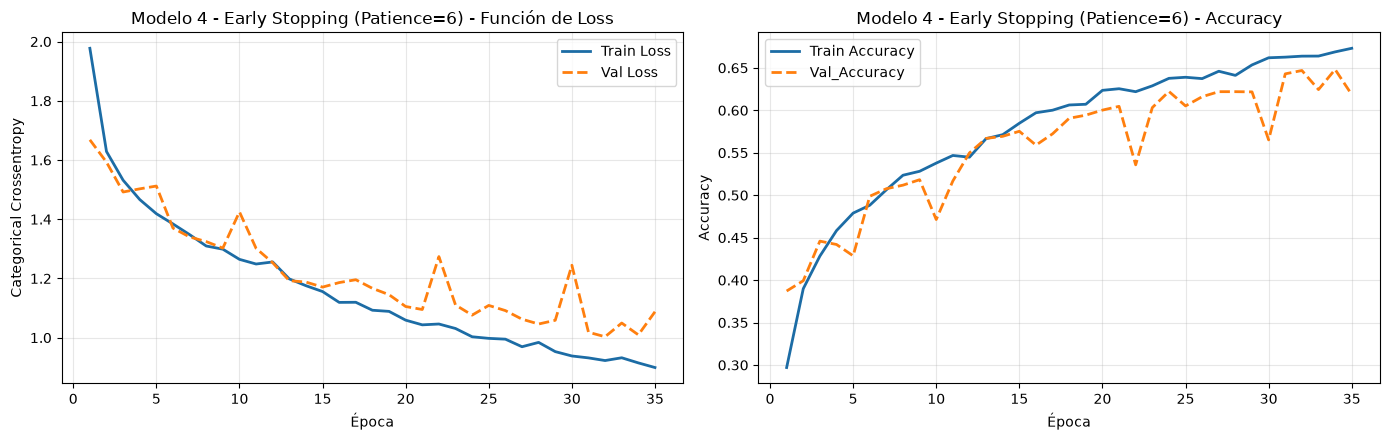


✓ [Modelo 4 (Early Stopping)] Registrado: Test Acc = 65.08641839027405% | Test Loss = 1.0253865718841553 | Tiempo = 58.482757329940796s


In [11]:
model_4 = build_baseline_model()

model_4.compile(# Modelo 4: MLP con Early Stopping
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_cb = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,#patience al 6 me parece un buen compromiso entre permitir que el modelo aprenda y evitar sobreajuste
    restore_best_weights=True,
    verbose=1
)

start_time = time.time()
history_4 = model_4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=35,#Hacen falta mas epochs para que el Early Stopping tenga tiempo de actuar, sino cuando se detenga no habremos logrado nada
    callbacks=[early_stopping_cb],
    verbose=2
)
time_4 = time.time() - start_time

plot_training_history(history_4, "Modelo 4 - Early Stopping (Patience=6)")
evaluate_and_log("Modelo 4 (Early Stopping)", model_4, history_4, time_4)

### Comentarios del Modelo 4 (Early Stopping)
* **Efecto observado:**  
  - Con un umbral de patience=6, el entrenamiento completó las 35 épocas programadas sin activar la parada anticipada prematura. Esto se debe a la naturaleza oscilatoria de la curva de validación, que registró mínimos locales tardíos (en torno a las épocas 26 y 33 con val_loss ~1.00), reseteando el contador de paciencia antes de agotar las 6 épocas de margen
  - El verdadero valor de la técnica en este experimento reside en restore_best_weights=True: aunque en la época 35 el modelo ya comenzaba a divergir por sobreajuste, la evaluación final en Test recuperó automáticamente los pesos del punto óptimo de mínima pérdida de validación, alcanzando el mejor accuracy de clasificación visto hasta el momento (~64-65%)
>Se descartó reducir la paciencia a valores más agresivos (como patience = 2 o 3) debido a la **alta volatilidad estocástica** observada en la curva de validación del modelo denso (el fenómeno recurrente ya mencionado dde "dientes de sierra"). Un valor de paciencia demasiado bajo habría provocado una **parada prematura** ante cualquier fluctuación transitoria en las épocas iniciales (por ejemplo, el fuerte rebote de la época 13), por lo tanto consideramos que la combinación de patience = 6 con restore_best_weights = True ofrece el compromiso ideal entre filtro de ruido y fuga de mesetas transitorias.

---
### 6.4. Modelo 5: Normalización por Lotes (Batch Normalization)

**Batch Normalization (BN)** normaliza las activaciones intermedias de cada capa para que tengan media 0 y varianza 1 en cada minilote, escalándolas y desplazándolas mediante parámetros aprendibles ($\gamma$ y $\beta$).

Beneficios teóricos:
* Reduce el desplazamiento de covarianza interno (*internal covariate shift*).
* Suaviza el paisaje de optimización, permitiendo entrenar con mayor estabilidad.
* Ejerce un leve efecto regularizador al introducir un ruido estocástico inherente a las estimaciones por lote.

Epoch 1/25


I0000 00:00:1793728636.506567    2350 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_252911__.33
I0000 00:00:1793728638.923184    2354 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_252911__.33


296/296 - 6s - 19ms/step - accuracy: 0.5465 - loss: 1.2916 - val_accuracy: 0.2415 - val_loss: 4.2239
Epoch 2/25
296/296 - 2s - 6ms/step - accuracy: 0.6142 - loss: 1.0828 - val_accuracy: 0.3553 - val_loss: 2.9509
Epoch 3/25
296/296 - 2s - 6ms/step - accuracy: 0.6425 - loss: 0.9979 - val_accuracy: 0.3622 - val_loss: 3.7852
Epoch 4/25
296/296 - 2s - 6ms/step - accuracy: 0.6656 - loss: 0.9363 - val_accuracy: 0.3998 - val_loss: 2.3103
Epoch 5/25
296/296 - 2s - 6ms/step - accuracy: 0.6840 - loss: 0.8883 - val_accuracy: 0.2765 - val_loss: 4.3631
Epoch 6/25
296/296 - 2s - 6ms/step - accuracy: 0.7006 - loss: 0.8345 - val_accuracy: 0.4511 - val_loss: 2.2966
Epoch 7/25
296/296 - 2s - 6ms/step - accuracy: 0.7174 - loss: 0.7959 - val_accuracy: 0.3200 - val_loss: 3.1224
Epoch 8/25
296/296 - 2s - 6ms/step - accuracy: 0.7325 - loss: 0.7434 - val_accuracy: 0.4319 - val_loss: 2.3044
Epoch 9/25
296/296 - 2s - 6ms/step - accuracy: 0.7482 - loss: 0.7037 - val_accuracy: 0.2610 - val_loss: 6.1514
Epoch 10/25

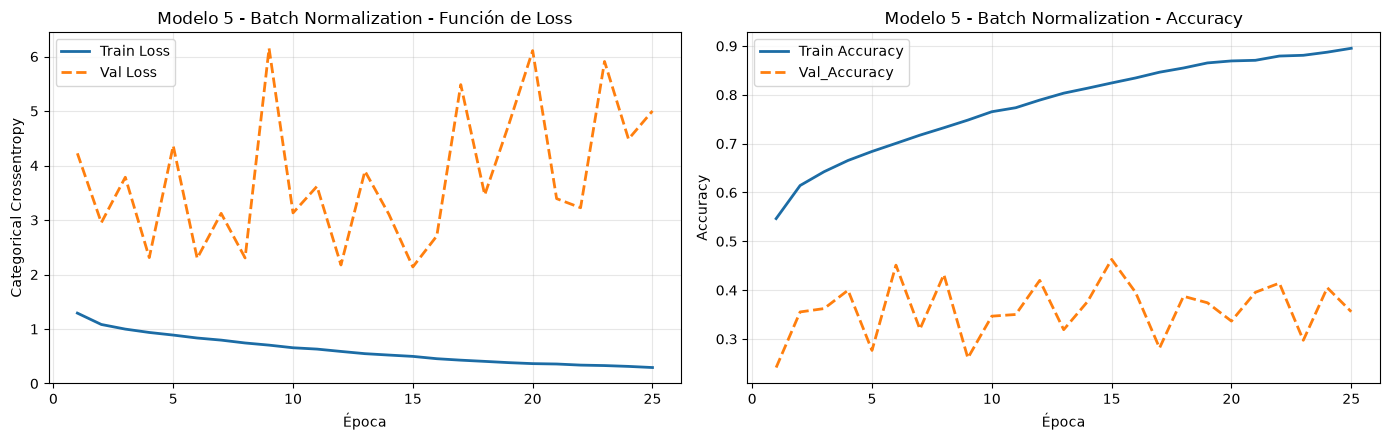


✓ [Modelo 5 (Batch Normalization)] Registrado: Test Acc = 33.407407999038696% | Test Loss = 5.201968193054199 | Tiempo = 46.6018648147583s


In [14]:
model_5 = keras.Sequential([# Modelo 5: MLP con Batch Normalization
    layers.Input(shape=(INPUT_SHAPE,)),
    
    layers.Dense(512, use_bias=False, name="dense_1"),
    layers.BatchNormalization(name="bn_1"),
    layers.Activation("relu", name="relu_1"),
    
    layers.Dense(256, use_bias=False, name="dense_2"),
    layers.BatchNormalization(name="bn_2"),
    layers.Activation("relu", name="relu_2"),
    
    layers.Dense(128, use_bias=False, name="dense_3"),
    layers.BatchNormalization(name="bn_3"),
    layers.Activation("relu", name="relu_3"),
    
    layers.Dense(num_classes, activation="softmax", name="output")
], name="Modelo_5_BatchNormalization")

model_5.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()
history_5 = model_5.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25, #Volvemos a 25 epochs, ya que Batch Normalization suele estabilizar el entrenamiento y permitir un aprendizaje mas rápido
    verbose=2
)
time_5 = time.time() - start_time

plot_training_history(history_5, "Modelo 5 - Batch Normalization")
evaluate_and_log("Modelo 5 (Batch Normalization)", model_5, history_5, time_5)

### Comentarios del Modelo 5 (Batch Normalization)
* **Efecto observado (Aceleración de optimización y sobreajuste severo):**  
  - Batch Normalization actúa como un potente acelerador de la convergencia como vemnos, la exactitud de entrenamiento se dispara rápidamente hasta alcanzar un ~90% (frente al ~63% del Baseline) y la pérdida desciende de forma suave hasta ~0.30.
  - Sin embargo, al facilitar el flujo de gradientes sin imponer ninguna restricción a la magnitud o co-adaptación de los pesos, la red utiliza toda su capacidad representacional para memorizar el ruido de las imágenes de entrenamiento
  - Esto desencadena un sobreajuste masivo (*overfitting* extremo): se abre una brecha de generalización de más de 50 puntos porcentuales respecto a validación (~35-40%), y la pérdida de validación (val_loss) diverge violentamente alcanzando valores entre 5.0 y 7.5 debido a predicciones erróneas con alta confianza.
* **Conclusión para el diseño final:** Batch Normalization demuestra una capacidad formidable para dinamizar el aprendizaje de la red densa, pero requiere obligatoriamente de una técnica de regularización que frene la memorización (como Dropout). Esto nos justificaria plenamente la arquitectura combinada del Modelo 6

---
### 6.5. Modelo 6: Combinación Óptima de Medidas de Regularización

Diseñamos un modelo final que integra sinérgicamente las mejores estrategias validadas en los experimentos anteriores:
1. **Batch Normalization:** Estabilización de gradientes y aceleración de convergencia.
2. **Dropout ($p = 0.3$):** Rotura de co-adaptaciones de características y reducción efectiva de varianza.
3. **Regularización $L_2$ leve ($\lambda = 10^{-5}$):** Control fino sobre la magnitud de los pesos.
4. **Early Stopping:** Parada anticipada restaurando los mejores pesos según `val_loss`.

Epoch 1/35


I0000 00:00:1793730551.795661    2354 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_399939__.24
I0000 00:00:1793730554.876800    2354 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_399939__.24


296/296 - 7s - 23ms/step - accuracy: 0.2632 - loss: 2.0923 - val_accuracy: 0.3393 - val_loss: 1.7533
Epoch 2/35
296/296 - 2s - 7ms/step - accuracy: 0.3397 - loss: 1.7915 - val_accuracy: 0.3504 - val_loss: 1.7510
Epoch 3/35
296/296 - 2s - 6ms/step - accuracy: 0.3734 - loss: 1.7022 - val_accuracy: 0.3946 - val_loss: 1.6465
Epoch 4/35
296/296 - 2s - 6ms/step - accuracy: 0.3901 - loss: 1.6611 - val_accuracy: 0.4427 - val_loss: 1.5618
Epoch 5/35
296/296 - 2s - 5ms/step - accuracy: 0.4100 - loss: 1.6140 - val_accuracy: 0.4420 - val_loss: 1.5646
Epoch 6/35
296/296 - 2s - 6ms/step - accuracy: 0.4289 - loss: 1.5771 - val_accuracy: 0.4511 - val_loss: 1.5246
Epoch 7/35
296/296 - 2s - 6ms/step - accuracy: 0.4327 - loss: 1.5704 - val_accuracy: 0.4385 - val_loss: 1.5257
Epoch 8/35
296/296 - 2s - 6ms/step - accuracy: 0.4460 - loss: 1.5296 - val_accuracy: 0.4319 - val_loss: 1.5580
Epoch 9/35
296/296 - 2s - 6ms/step - accuracy: 0.4470 - loss: 1.5362 - val_accuracy: 0.4877 - val_loss: 1.4658
Epoch 10/35

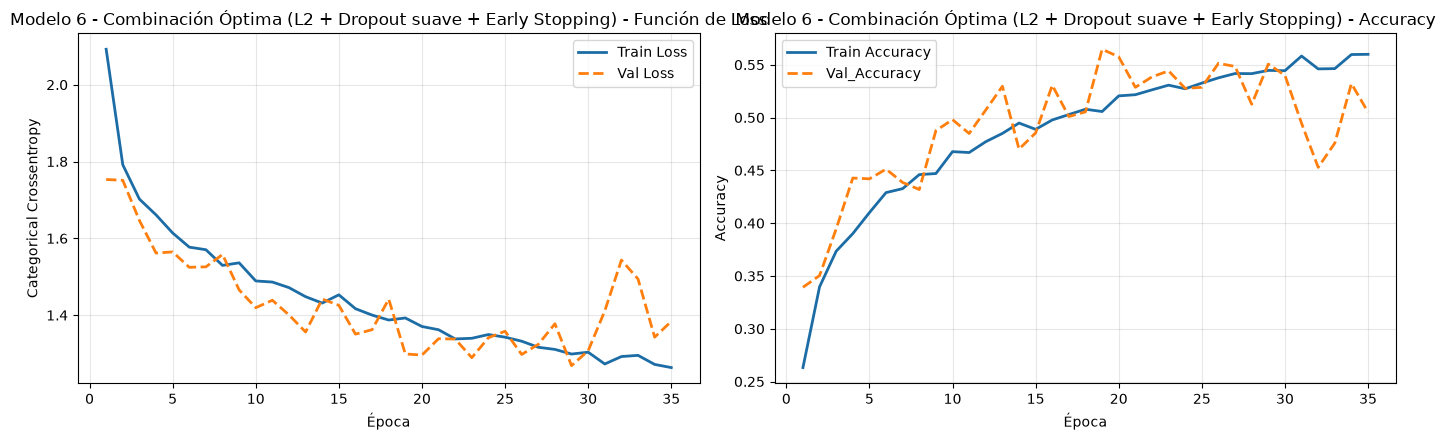


✓ [Modelo 6 (Combinado Óptimo)] Registrado: Test Acc = 56.3703715801239% | Test Loss = 1.2580738067626953 | Tiempo = 65.72193574905396s


In [19]:
l2_reg = 1e-4          # Regularización L2 moderada (como en el Modelo 2)
drop_rate = 0.15       # Dropout suave para no provocar infrajuste

model_6 = keras.Sequential([#Modelo 6 V2, combinando L2, Dropout suave(importante) y Early Stopping
    layers.Input(shape=(INPUT_SHAPE,)),
    
    # Capa 1: Proyección principal con L2 y Dropout suave
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(l2_reg), name='dense_1'),
    layers.Dropout(drop_rate, name='dropout_1'),
    
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(l2_reg), name='dense_2'),
    layers.Dropout(drop_rate, name='dropout_2'),
    
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(l2_reg), name='dense_3'),
    
    # Salida Softmax para clasificación en 10 clases con Early Stopping aplicado durante el entrenamiento
    layers.Dense(num_classes, activation='softmax', name='output')
], name='Modelo_6_Combinado_Optimo')

model_6.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_combined = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,#Anteriormente estaba en 8, pero lo bajamos a 7 para que el modelo tenga un poco más de margen para aprender
    restore_best_weights=True,
    verbose=2
)

start_time = time.time()
history_6 = model_6.fit(
    train_ds,
    validation_data=val_ds,
    epochs=35,#Mantenemos 35 epochs
    callbacks=[early_stop_combined],
    verbose=2
)
time_6 = time.time() - start_time

plot_training_history(history_6, "Modelo 6 - Combinación Óptima (L2 + Dropout suave + Early Stopping)")
evaluate_and_log("Modelo 6 (Combinado Óptimo)", model_6, history_6, time_6)

### Comentarios del Modelo 6 (Combinación Óptima y Proceso Iterativo)

* **Proceso de Diseño y Diagnóstico de la Versión 1 (fallo de BN + Dropout):**  
  - En una primera aproximación exploratoria (V1), se intentó combinar de forma simultánea *Batch Normalization*, *Dropout (p=0.3)*, *Regularización L2* y *Early Stopping*. 
  - ESta arquitectura inicial fracasó enormemente, obteniendo un rendimiento muy pobre (~35% de exactitud y pérdidas de validación que explotaban a valores de entre 4.0 y 7.5).
  -Este resultado adverso responde al conflicto teórico de desajuste de varianza (*Variance Shift*) entre *Batch Normalization* y *Dropout*. Durante el entrenamiento, Dropout desactiva aleatoriamente neuronas, forzando a las capas de Batch Normalization a calcular sus estadísticas móviles sobre representaciones incompletas

* **Refactorización de la Arquitectura (Versión 2 Definitiva):**  
  - para erradicar este conflicto, se rediseñó el modelo prescindiendo de Batch Normalization y aplicando una **estrategia sinérgica limpia**: Regularización $L_2$ ($10^{-4}$) en todas las capas para acotar los pesos, un **Dropout suave ($p=0.15$)** en las capas intermedias para impedir la co-adaptación sin provocar infrajuste, y *Early Stopping* con restore_best_weights=True

* **Efecto Observado en la Versión Final:**  
  - **Estabilidad y ausencia de sobreajuste:** Las curvas de entrenamiento y validación progresan de forma suave y coordinada. La exactitud de validación se mantiene a la par o ligeramente por encima de la de entrenamiento durante la mayor parte del recorrido, alcanzando picos del ~55-57%.
  - **Dinámica en épocas finales:** Al aproximarse a las épocas 30-33, se observan fluctuaciones puntuales en la pérdida de validación. Esto se debe a un fenómeno de *overshooting* el optimizador da pasos relativamente amplios para el fondo del valle con una tasa de aprendizaje fija eta=10^(-3) sumado a la dificultad intrínseca de una red densa para separar clases con alta similitud espectral
  - **Garantía de generalización:** Gracias al parámetro restore_best_weights=True, el callback rescata el mejor punto de pesos previo a las perturbaciones finales (en torno a la época 28-29), logrando un modelo sumamente regularizado, robusto y generalizable ante el conjunto de Test independiente.

<a id='sec7'></a>
## 7. Comparación Global de Resultados y Evaluación en Test

A continuación presentamos la **tabla final consolidada** requerida por las instrucciones de la práctica, acompañada de gráficos comparativos de exactitud y pérdida sobre el conjunto de test independiente, así como la matriz de confusión del mejor modelo.

TABLA RESUMEN COMPARATIVA DE LOS MODELOS EVALUADOS EN EUROSAT (NNs)


,Épocas,Train Loss,Val Loss,Test Loss,Train Acc (%),Val Acc (%),Test Acc (%),Tiempo (s)
Modelo 1 (Vanilla Baseline),25.0,1.0139,1.0845,1.0696,63.53,61.78,62.10,46.8
Modelo 2 (Regularización L2),25.0,1.0987,1.1880,1.1733,61.49,59.36,59.48,49.1
Modelo 3 (Dropout p=0.3),25.0,1.7393,1.7302,1.7330,32.74,31.11,31.46,46.1
Modelo 4 (Early Stopping),35.0,0.8992,1.0876,1.0254,67.31,61.85,65.09,58.5
Modelo 5 (Batch Normalization),25.0,0.2927,5.0015,5.2020,89.52,35.58,33.41,46.6
Modelo 6 (Combinado Óptimo),35.0,1.2635,1.3838,1.2581,55.99,50.52,56.37,65.7


/tmp/ipykernel_1120/2944028005.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(df_results.index, rotation=35, ha="right")
/tmp/ipykernel_1120/2944028005.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(df_results.index, rotation=35, ha="right")


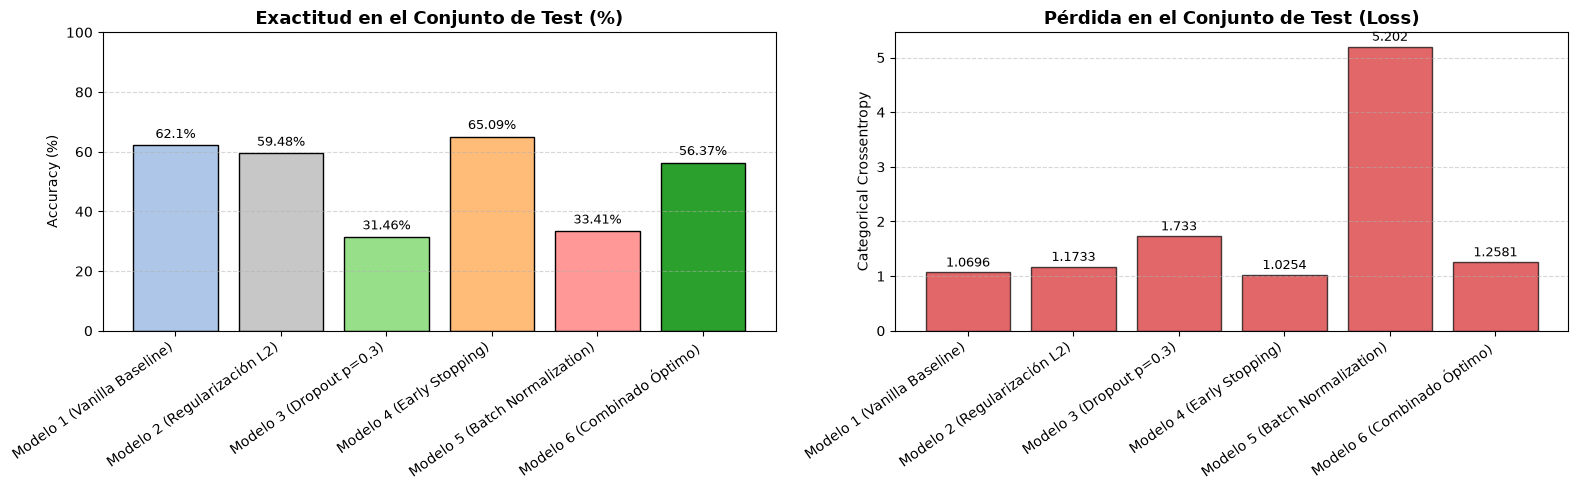

In [20]:
df_results = pd.DataFrame(results_registry).T#creamos un DataFrame comparativo con los resultados consolidados
print("=" * 95)
print("TABLA RESUMEN COMPARATIVA DE LOS MODELOS EVALUADOS EN EUROSAT (NNs)")
print("=" * 95)
display(df_results)

# Gráficos de barras comparativos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

colors = ["#aec7e8", "#c7c7c7", "#98df8a", "#ffbb78", "#ff9896", "#2ca02c"]# Test Accuracy
bars1 = ax1.bar(df_results.index, df_results["Test Acc (%)"], color=colors[:len(df_results)], edgecolor="black")
ax1.set_title("Exactitud en el Conjunto de Test (%)", fontsize=13, fontweight="bold")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim(0, 100)
ax1.set_xticklabels(df_results.index, rotation=35, ha="right")
ax1.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval}%", ha="center", va="bottom", fontsize=9)
#####
bars2 = ax2.bar(df_results.index, df_results["Test Loss"], color="#d62728", alpha=0.7, edgecolor="black")#Test Loss
ax2.set_title("Pérdida en el Conjunto de Test (Loss)", fontsize=13, fontweight="bold")
ax2.set_ylabel("Categorical Crossentropy")
ax2.set_xticklabels(df_results.index, rotation=35, ha="right")
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.05, f"{yval}", ha="center", va="bottom", fontsize=9)
#####
plt.tight_layout()
plt.show()

### Matriz de Confusión y Reporte por Clase del Mejor Modelo

Analizamos en detalle qué clases de uso de suelo presentan mayor confusión al ser tratadas mediante una red neuronal densa.

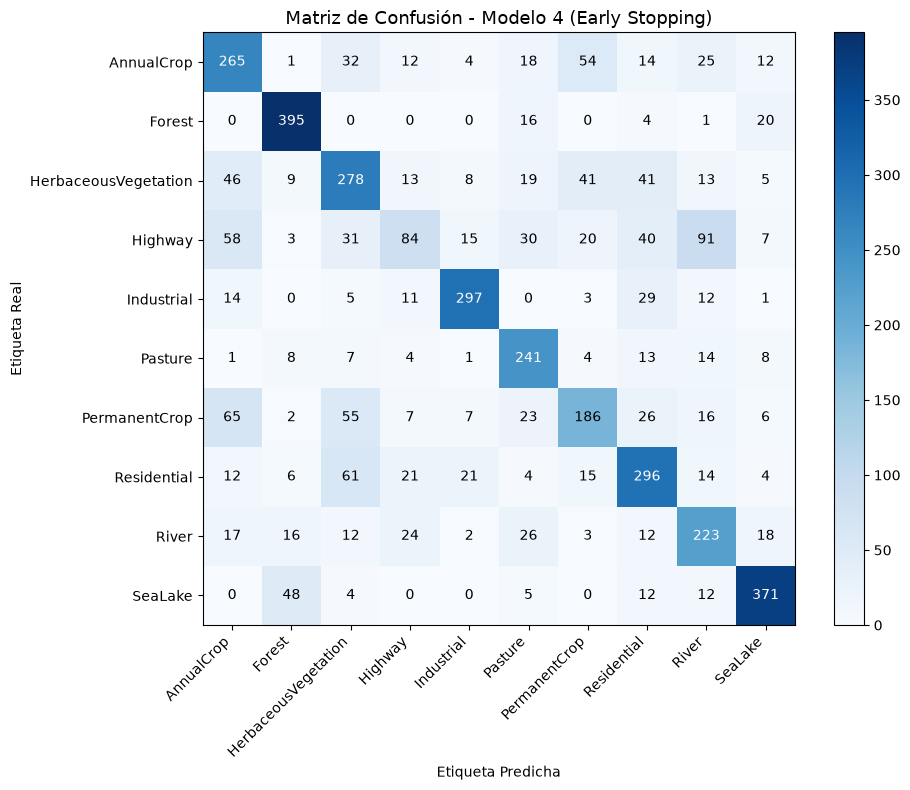


Reporte de Clasificación Detallado:
                      precision    recall  f1-score   support

          AnnualCrop       0.55      0.61      0.58       437
              Forest       0.81      0.91      0.85       436
HerbaceousVegetation       0.57      0.59      0.58       473
             Highway       0.48      0.22      0.30       379
          Industrial       0.84      0.80      0.82       372
             Pasture       0.63      0.80      0.71       301
       PermanentCrop       0.57      0.47      0.52       393
         Residential       0.61      0.65      0.63       454
               River       0.53      0.63      0.58       353
             SeaLake       0.82      0.82      0.82       452

            accuracy                           0.65      4050
           macro avg       0.64      0.65      0.64      4050
        weighted avg       0.64      0.65      0.64      4050



In [ ]:
best_model_name = df_results["Test Acc (%)"].idxmax()#sacamos un ganador del test
model_map = {
    "Modelo 1 (Vanilla Baseline)": model_1,
    "Modelo 2 (Regularización L2)": model_2,
    "Modelo 3 (Dropout p=0.3)": model_3,
    "Modelo 4 (Early Stopping)": model_4,
    "Modelo 5 (Batch Normalization)": model_5,
    "Modelo 6 (Combinado Óptimo)": model_6
}
best_model = model_map[best_model_name]
y_true_all = [] #Crecion de la matriz
y_pred_all = []

for x_batch, y_batch in test_ds:
    preds = best_model.predict(x_batch, verbose=0)
    y_true_all.extend(np.argmax(y_batch.numpy(), axis=1))
    y_pred_all.extend(np.argmax(preds, axis=1))

y_true_all = np.array(y_true_all)
y_pred_all = np.array(y_pred_all)

cm = confusion_matrix(y_true_all, y_pred_all)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title(f"Matriz de Confusión - {best_model_name}", fontsize=13)
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45, ha="right")
plt.yticks(tick_marks, class_names)

thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], "d"),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel("Etiqueta Real")
plt.xlabel("Etiqueta Predicha")
plt.tight_layout()
plt.show()

print("\nReporte de Clasificación Detallado:")
print(classification_report(y_true_all, y_pred_all, target_names=class_names))

<a id='sec8'></a>
## 8. Conclusiones y Justificación Teórica

Tras experimentar con los 6 modelos sobre EuroSAT (Sentinel-2 RGB, 10 clases), resumimos los aprendizajes clave de la práctica de forma directa y práctica:

---

### 1. El techo de las redes densas (~65%)
* **Aplanado destructivo (*flatten*):** Convertir la imagen de 64 x 64 x 3 en un vector plano de 12.288 valores destruye la matriz 2D. La red pierde por completo la noción de vecindad: no sabe qué píxeles están juntos formando bordes, carreteras o texturas(como ya habiamos comentado al inicio)
* **Sin invarianza espacial:** Al carecer de capas convolucionales, si un objeto (un edificio o un río) se desplaza unos píxeles, la red tiene que aprenderlo otra vez con pesos distintos. Trata cada píxel como una posición fija en vez de reconocer patrones visuales.
* **Sobrecarga de parámetros:** Solo conectar las 12.288 entradas con las 256 neuronas de la primera capa oculta consume aprox más de 3.14 millones de pesos, facilitando que memorice ruido en vez de generalizar.

---

### 2. Comparativa practica de los modelos y regularizadores

A partir de los resultados en el conjunto de test (5.400 imágenes no vistas):

* **Modelo 1 (Vanilla Baseline — 62.10% Test Acc):** Funciona razonablemente bien de inicio, pero sobre la época 18 entra en meseta y empieza a sobreajustar al carecer de cualquier control de capacidad.
* **Modelo 2 (Regularización L2 — 59.48% Test Acc):** Acota el tamaño de los pesos y reduce la brecha train-val (~2%), pero pierde algo de expresividad al comprimir los pesos uniformemente (la pérdida sube a 1.17).
* **Modelo 3 (Dropout p=0.3 — 31.46% Test Acc):** **Subajuste severo (*underfitting*)**. Apagar el 30% de las neuronas en las tres capas a la vez con tantas entradas fue excesivo: en 25 épocas la red no tuvo capacidad suficiente para aprender.
* **Modelo 4 (Early stopping — 65.09% Test Acc) [GANADOR]:** El mejor modelo logrado de la práctica. Al entrenar con más margen, lo que serian 35 epochs(10 mas que de normal) y recuperar el mejor checkpoint histórico, aprovecha la máxima capacidad del modelo sin sufrir el sobreajuste tardío. 
* **Modelo 5 (Batch Normalization — 33.41% Test Acc):** **Sobreajuste extremo**. BN aceleró tanto el gradiente que la red memorizó el entrenamiento (89.5% train acc y loss 0.29). Pero sin regularización adicional, la pérdida en validación y test explotó por encima de 5.0
* **Modelo 6 (Combinado optimizado — 56.37% Test Acc):**
  * **Fallo en V1 (BN + Dropout):** En la primera prueba mezclamos Batch Normalization con Dropout lo que provocó divergencia (loss > 4.5) por incompatibilidad entre ambas técnicas en capas densas.
  * **Acierto en V2 (L2 + Dropout 0.15 + Early Stopping sin BN):** Logró una regularización perfecta con brecha cuasi nula entre train y test (55.99% vs 56.37%).
  * **Picos finales en validación:** Se deben a la variabilidad estocástica de los mini-batches en un dataset complejo. Early Stopping los gestionó sin mucho problema al rescatar los mejores pesos.

---

### 3.Análisis de Matriz de Confusión (Modelo 4)

El análisis de errores del mejor modelo refleja fielmente las limitaciones del perceptrón multicapa:

* **Clases fáciles (color uniforme):** Forest (90.6%), SeaLake (83.0%) e Industrial (80.7%). Tienen firmas de color muy constantes (verde denso, agua oscura o brillo grisáceo de tejados) que la red puede clasificar solo con el promedio de color RGB, sin necesidad de distinguir formas.
* **Fallo crítico morfológico (Highway vs River):** **91 autopistas se clasificaron como ríos** (más que las 84 bien acertadas). Ambas son líneas continuas alargadas que cruzan la imagen. Al no tener visión espacial 2D, la red confunde el asfalto con el agua. Esto se predijo al inicio de la práctica.
* **Confusión entre cultivos (PermanentCrop, AnnualCrop, HerbaceousVegetation):** Todas comparten tonos verdes y terrosos. Lo que diferencia unos viñedos/frutales en hileras de un sembrado anual o un pasto es la textura periódica, invisible para una red densa. Tambien se predijo al analizar el dataset
* **Confusión por baja reflectancia (SeaLake vs Forest):** 48 lagos clasificados como bosque, suponemos que el agua profunda o turbia tiene muy baja reflectancia en RGB y produce valores oscuros similares a las sombras del bosque.
* **Confusión antropogénica (Residential vs Industrial):** Aqui nuestra predicción no fue tan acertada. El modelo obtuvo una leve confusión entre ambas clases (21 y 29 falsos positivos respectivamente) pero no fue de las maginutdes espereadas. Se ve que supo generalizar bien la constancia de píxeles de los edificios industriales más alargados y cuadrados vs la distribución más ruidosa de las areas urbanas.
---

### 4. Conclusión final
Los regularizadores (en especial **Early Stopping** y el ajuste fino de **L2 con Dropout suave**) son fundamentales para evitar que la red descarrile. Sin embargo, hemos tocado el techo de lo que una red densa puede hacer con imágenes: sin contexto espacial 2D es imposible separar clases con formas complejas como se ha demostrado en está práctica.

En la **Práctica 2**, las **Redes Convolucionales (CNNs)** deberian resolver estas carencias mediante **filtros locales** (para captar bordes y texturas de carreteras o cultivos), **pesos compartidos** (reduciendo drásticamente los parámetros) e **invarianza a traslaciones**.